# הנדסת פיצ'רים: עמודות הנהג
מחברת עבודה לבניית הפונקציה add_driver_features. הפונקציה מקבלת את הטבלה אחרי clean_driver_cols ומוסיפה עמודות חדשות.
העמודות המקוריות נשארות. הפונקציה תיכנס בסוף לתוך prepare_data במחברת הראשית.

In [1]:
# ספריות, קבוע האקראיות וטעינת הדאטה
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
df = pd.read_csv("dataset.csv")
y = df["annual_claim_cost"]

In [2]:
# פונקציות עזר לניקוי: אחת לעמודות מספר ואחת לעמודות טקסט, שעובדות גם על עמודה ריקה לגמרי
def to_num(s):
    # המרה למספר אחרי הסרת פסיקים ורווחים, וערך אינסופי הופך לחסר
    out = pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")
    return out.replace([np.inf, -np.inf], np.nan)

def clean_text(s, case="lower"):
    # הסרת רווחים ואחידות אותיות, וערך חסר או מחרוזת ריקה הופכים לחסר
    out = s.astype(str).str.strip()
    out = out.str.upper() if case == "upper" else out.str.lower()
    return out.where(s.notna() & (out != ""))

In [3]:
# פונקציית הניקוי הסופית של עמודות הנהג ההיסטוריה והגאוגרפיה
def clean_driver_cols(df):
    df = df.copy()

    # מדינה וסוג אזור: איחוד כתיבה, וערך חסר או ריק נשאר חסר
    df["country"] = clean_text(df["country"], case="upper")
    df["area_type"] = clean_text(df["area_type"], case="lower")

    # צפיפות: המרה למספר, וערך שאינו חיובי הופך לחסר
    df["region_density"] = to_num(df["region_density"])
    df.loc[df["region_density"] <= 0, "region_density"] = np.nan

    # חומרת חורף: ערך מחוץ לטווח אפס עד עשר הופך לחסר
    df["winter_severity"] = to_num(df["winter_severity"])
    df.loc[(df["winter_severity"] < 0) | (df["winter_severity"] > 10), "winter_severity"] = np.nan

    # גיל: גיל מתחת לשש עשרה או מעל מאה הופך לחסר
    df["driver_age"] = to_num(df["driver_age"])
    df.loc[(df["driver_age"] < 16) | (df["driver_age"] > 100), "driver_age"] = np.nan

    # מגדר: מיפוי לשני ערכים תקניים, וערך לא מוכר הופך לחסר
    gender_map = {"m": "M", "male": "M", "f": "F", "female": "F"}
    df["gender"] = clean_text(df["gender"], case="lower").map(gender_map)

    # מצב משפחתי: רק ארבעת הערכים החוקיים נשארים, וכל ערך אחר הופך לחסר
    valid_marital = ["single", "married", "divorced", "widowed"]
    df["marital_status"] = clean_text(df["marital_status"], case="lower")
    df.loc[~df["marital_status"].isin(valid_marital), "marital_status"] = np.nan

    # ותק רישיון: ערך שלילי הופך לחסר, וגם ותק שמשמעותו קבלת רישיון לפני גיל שש עשרה
    df["license_years"] = to_num(df["license_years"])
    df.loc[df["license_years"] < 0, "license_years"] = np.nan
    df.loc[df["driver_age"] - df["license_years"] < 16, "license_years"] = np.nan

    # תביעות בעבר: ערך שלילי הופך לחסר וערך מעל שש הופך לשש
    df["prior_claims_5y"] = to_num(df["prior_claims_5y"])
    df.loc[df["prior_claims_5y"] < 0, "prior_claims_5y"] = np.nan
    df["prior_claims_5y"] = df["prior_claims_5y"].clip(upper=6)

    # נהג עם אפס שנות ותק לא יכול היה לצבור תביעות בעבר ולכן ערך חסר אצלו הופך לאפס
    df.loc[(df["license_years"] == 0) & (df["prior_claims_5y"].isna()), "prior_claims_5y"] = 0

    # שנים ללא תביעה: ערך שלילי או גדול מוותק הרישיון הופך לחסר וערך מעל שלושים הופך לשלושים
    df["no_claims_years"] = to_num(df["no_claims_years"])
    df.loc[df["no_claims_years"] < 0, "no_claims_years"] = np.nan
    df.loc[df["no_claims_years"] > df["license_years"], "no_claims_years"] = np.nan
    df["no_claims_years"] = df["no_claims_years"].clip(upper=30)

    # דוחות תנועה: ערך שלילי הופך לחסר
    df["violations_3y"] = to_num(df["violations_3y"])
    df.loc[df["violations_3y"] < 0, "violations_3y"] = np.nan

    return df

In [4]:
# הרצת הניקוי ובדיקה שהתוצאה זהה למה שקיבלנו במחברת הניקוי
df_clean = clean_driver_cols(df)
DRIVER_COLS = ["country", "area_type", "region_density", "winter_severity", "driver_age", "gender",
               "marital_status", "license_years", "prior_claims_5y", "no_claims_years", "violations_3y"]

print("Shape:", df_clean.shape)
print(df_clean[DRIVER_COLS].isna().sum()[lambda s: s > 0])

Shape: (45000, 30)
license_years       153
prior_claims_5y    1955
dtype: int64


## פיצ'ר 1: גיל בריבוע
הקשר בין גיל לעלות בצורת U (סעיפים 2.3 ו-2.4), וקו ישר לא מצליח לתאר אותו.
כשמוסיפים עמודה של גיל בריבוע לצד הגיל, המודל הלינארי יכול ליצור עקומה: יורדת בהתחלה ועולה בסוף.

Curve coefficients: age -222.28 | age squared 1.841


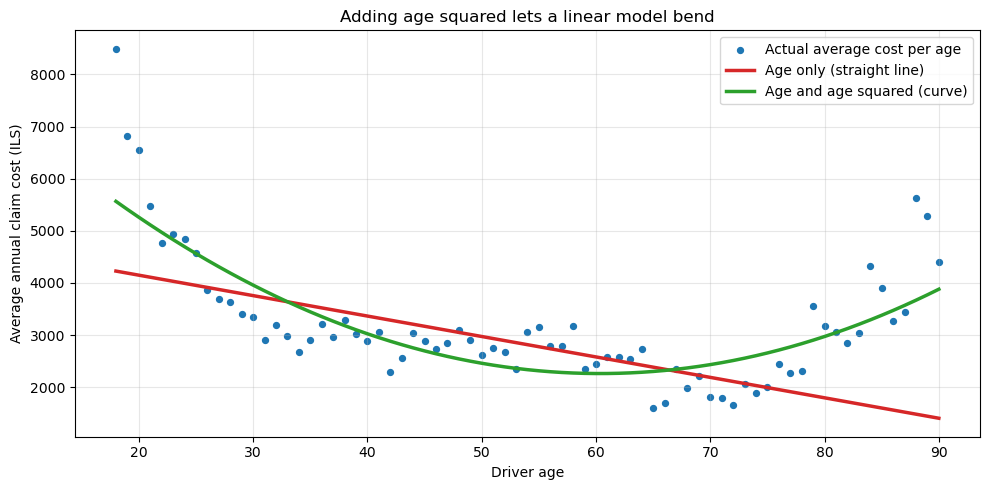

In [5]:
# השוואה בין קו ישר לפי הגיל לבין עקומה שמשתמשת גם בגיל בריבוע
from sklearn.linear_model import LinearRegression

df_clean["age_sq"] = df_clean["driver_age"] ** 2

line_model = LinearRegression().fit(df_clean[["driver_age"]], y)
curve_model = LinearRegression().fit(df_clean[["driver_age", "age_sq"]], y)
print("Curve coefficients: age", round(curve_model.coef_[0], 2), "| age squared", round(curve_model.coef_[1], 3))

ages = pd.DataFrame({"driver_age": np.arange(18, 91)})
ages["age_sq"] = ages["driver_age"] ** 2
mean_by_age = y.groupby(df_clean["driver_age"]).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(mean_by_age.index, mean_by_age.values, s=18, color="tab:blue", label="Actual average cost per age")
ax.plot(ages["driver_age"], line_model.predict(ages[["driver_age"]]), color="tab:red", linewidth=2.5, label="Age only (straight line)")
ax.plot(ages["driver_age"], curve_model.predict(ages), color="tab:green", linewidth=2.5, label="Age and age squared (curve)")
ax.set_title("Adding age squared lets a linear model bend")
ax.set_xlabel("Driver age")
ax.set_ylabel("Average annual claim cost (ILS)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### מסקנה לגבי גיל בריבוע
- **נוסחה:** age_sq = driver_age בריבוע. העמודה המקורית נשארת.
- **מוטיבציה:** הקשר בין גיל לעלות בצורת U, וקו ישר מפספס אותו (סעיף 2.3).
- **תוצאה:** עם גיל וגיל בריבוע, המודל הלינארי יוצר עקומה עם שפל סביב גיל 60, קרוב לממוצעים האמיתיים.
- **המקדם קטן (1.84) כי הסקאלה גדולה** (60 בריבוע הוא 3,600). לכן לפני ה-ElasticNet יש סקיילינג ב-Pipeline.
- **מה עוד חסר:** גילאי 18 עד 20 יקרים יותר ממה שהעקומה מתארת. לשם כך בא הפיצ'ר הבא, דגל נהג צעיר.

## פיצ'ר 2: דגל נהג צעיר
העקומה של גיל בריבוע עדיין נמוכה מהעלות האמיתית אצל הצעירים מאוד.
דגל של אפס או אחד יאפשר למודל לתת תוספת קבועה לנהגים צעירים. קודם נבדוק בדאטה מאיזה גיל הסיכון יורד, כדי לבחור את הסף.

In [6]:
# עלות ממוצעת ואחוז נהגים יקרים לכל גיל בין שמונה עשרה לשלושים ושתיים, כדי לבחור סף לנהג צעיר
young_range = df_clean["driver_age"] <= 32
y[young_range].groupby(df_clean.loc[young_range, "driver_age"]).agg(
    avg_cost="mean",
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_expensive,drivers
driver_age,,,
18.0,8492.058,0.216,412
19.0,6823.096,0.190,426
20.0,6544.493,0.189,503
21.0,5481.038,0.165,480
22.0,4770.518,0.148,514
23.0,4941.615,0.134,574
24.0,4839.578,0.160,633
25.0,4576.658,0.139,676
26.0,3867.521,0.105,685


In [7]:
# בדיקה בתיקוף צולב: כמה כל אפשרות של דגל נהג צעיר משפרת את השגיאה מעבר לגיל ולגיל בריבוע
from sklearn.model_selection import KFold, cross_val_score

df_clean["is_young_21"] = (df_clean["driver_age"] <= 21).astype(int)
df_clean["is_young_25"] = (df_clean["driver_age"] <= 25).astype(int)
kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

options = {
    "age + age squared": ["driver_age", "age_sq"],
    "+ young up to 21": ["driver_age", "age_sq", "is_young_21"],
    "+ young up to 25": ["driver_age", "age_sq", "is_young_25"],
    "+ both flags": ["driver_age", "age_sq", "is_young_21", "is_young_25"],
}
for name, cols in options.items():
    rmse = -cross_val_score(LinearRegression(), df_clean[cols], y, cv=kf, scoring="neg_root_mean_squared_error")
    print(f"{name:20} RMSE {rmse.mean():8.1f} | std {rmse.std():5.1f}")

age + age squared    RMSE   7490.6 | std 447.8
+ young up to 21     RMSE   7482.9 | std 445.0
+ young up to 25     RMSE   7484.9 | std 445.9
+ both flags         RMSE   7481.3 | std 444.4


### מסקנה לגבי דגל נהג צעיר
- **נוסחה:** is_young = 1 אם הגיל עד 21 כולל, אחרת 0.
- **מוטיבציה:** בטבלה יש שתי מדרגות. גילאי 18 עד 21 עולים 6,770 בממוצע (18.9% יקרים), גילאי 22 עד 25 עולים 4,775 (14.5%), וגילאי 26 עד 29 עולים 3,646 (11%). העקומה של גיל בריבוע מפספסת את הקפיצה החדה של 18 עד 21.
- **בחירת הסף:** בתיקוף צולב, דגל עד 21 נתן את השגיאה הנמוכה ביותר מבין הדגלים הבודדים. שני דגלים שיפרו רק ב-1.6, ולכן נשארנו עם דגל אחד.
- **הסתייגות:** כל השיפורים (2 עד 9) קטנים מסטיית התקן בין ה-folds (445). הגיל לבדו מסביר מעט, והתרומה האמיתית תיבדק במודל המלא.

## פיצ'ר 3: הגיל בקבלת הרישיון
נוסחה: גיל הנהג פחות ותק הרישיון. ההשערה: מי שהוציא רישיון בגיל מאוחר נוהג אחרת ממי שנוהג מגיל צעיר.
נבדוק את הקשר לעלות בכל הדאטה, וגם בתוך כל קבוצת גיל, כי גיל הנהג עלול להיות משתנה מבלבל.

In [8]:
# חישוב הגיל בקבלת הרישיון ובדיקת הקשר לעלות בכל הדאטה ובתוך כל קבוצת גיל
license_age = df_clean["driver_age"] - df_clean["license_years"]
print("Missing:", license_age.isna().sum())
print(license_age.describe().round(1), "\n")

license_group = pd.cut(license_age, bins=[15, 17, 18, 20, 25, 30, 40, 100])
print(y.groupby(license_group, observed=True).agg(
    avg_cost="mean",
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3), "\n")

age_group = pd.cut(df_clean["driver_age"], bins=[17, 29, 44, 64, 90], labels=["18-29", "30-44", "45-64", "65-90"])
license_band = pd.cut(license_age, bins=[15, 18, 25, 100], labels=["16-18", "19-25", "26+"])
pd.crosstab(age_group, license_band, values=y, aggfunc="mean").round(0)

Missing: 153
count    44847.0
mean        19.2
std          3.4
min         17.0
25%         17.0
50%         18.0
75%         20.0
max         47.0
dtype: float64 

           avg_cost  share_expensive  drivers
(15, 17]   2987.720            0.090    12617
(17, 18]   3113.451            0.094    11657
(18, 20]   3115.081            0.093    12540
(20, 25]   2998.768            0.093     6297
(25, 30]   2890.154            0.089      786
(30, 40]   2999.055            0.092      749
(40, 100]  2285.303            0.065      201 



col_0,16-18,19-25,26+
driver_age,,,
18-29,4646.0,5110.0,4906.0
30-44,2947.0,2892.0,3468.0
45-64,2785.0,2753.0,2549.0
65-90,2279.0,2334.0,1896.0


### מסקנה לגבי הגיל בקבלת הרישיון: נדחה
- **בכל הדאטה אין קשר:** בכל הקבוצות שבהן רוב הנהגים, העלות דומה (2,890 עד 3,115). רק מי שהוציא רישיון אחרי גיל 40 זול יותר (2,285), אבל אלה 201 נהגים בלבד, וכולם מבוגרים היום, כך שהגיל הנוכחי מסביר את זה.
- **בתוך כל קבוצת גיל אין כיוון קבוע:** בגילאי 30 עד 44 רישיון מאוחר יקר יותר, ובגילאי 45 ומעלה הוא זול יותר.
- **החלטה:** הפיצ'ר לא נכנס למודל. מה שמשפיע הוא כמה זמן הנהג נוהג, ולא באיזה גיל התחיל. לכן הפיצ'ר הבא הוא דגל נהג חדש.

## פיצ'ר 4: דגל נהג חדש
ההשערה: מה שמשפיע הוא כמה זמן הנהג נוהג, ולא באיזה גיל התחיל. נהג עם מעט שנות ותק מסוכן יותר.
נבדוק את העלות לפי שנות הוותק כדי לבחור סף, ואחר כך נבדוק שהקשר נשמר גם בתוך כל קבוצת גיל.

In [9]:
# עלות לפי שנות ותק, והשוואה בין נהגים חדשים לוותיקים בתוך כל קבוצת גיל
print(y.groupby(df_clean["license_years"].clip(upper=8)).agg(
    avg_cost="mean",
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3), "\n")

age_group5 = pd.cut(df_clean["driver_age"], bins=[17, 21, 25, 29, 39, 90], labels=["18-21", "22-25", "26-29", "30-39", "40+"])
experience = np.where(df_clean["license_years"] <= 1, "new (0-1 years)", "experienced (2+ years)")
pd.crosstab(age_group5, experience, values=y, aggfunc="mean", rownames=["driver age"], colnames=["experience"]).round(0)

               avg_cost  share_expensive  drivers
license_years                                    
0.0            7014.383            0.192     1187
1.0            6627.577            0.167      456
2.0            4751.684            0.149      550
3.0            5977.021            0.180      516
4.0            4890.071            0.169      534
5.0            4248.394            0.109      625
6.0            3844.115            0.127      620
7.0            3634.029            0.103      720
8.0            2764.979            0.085    39639 



experience,experienced (2+ years),new (0-1 years)
driver age,,
18-21,5068.0,7976.0
22-25,4717.0,5250.0
26-29,3576.0,5428.0
30-39,3015.0,4639.0
40+,2628.0,2833.0


In [10]:
# בדיקה בתיקוף צולב של שלושה ספים לדגל נהג חדש, מעבר לפיצ'רי הגיל שכבר בחרנו
df_clean["is_young"] = (df_clean["driver_age"] <= 21).astype(int)
base_cols = ["driver_age", "age_sq", "is_young"]

rmse = -cross_val_score(LinearRegression(), df_clean[base_cols], y, cv=kf, scoring="neg_root_mean_squared_error")
print(f"{'age features only':24} RMSE {rmse.mean():8.1f} | std {rmse.std():5.1f}")
for k in [0, 1, 2]:
    df_clean["new_tmp"] = (df_clean["license_years"] <= k).astype(int)
    rmse = -cross_val_score(LinearRegression(), df_clean[base_cols + ["new_tmp"]], y, cv=kf, scoring="neg_root_mean_squared_error")
    print(f"{'+ new driver up to ' + str(k):24} RMSE {rmse.mean():8.1f} | std {rmse.std():5.1f}")
df_clean = df_clean.drop(columns="new_tmp")

age features only        RMSE   7482.9 | std 445.0
+ new driver up to 0     RMSE   7478.8 | std 446.3
+ new driver up to 1     RMSE   7478.3 | std 441.6
+ new driver up to 2     RMSE   7480.6 | std 444.9


### מסקנה לגבי דגל נהג חדש
- **נוסחה:** is_new_driver = 1 אם ותק הרישיון 0 או 1 שנים, אחרת 0. אם הוותק חסר, גם הדגל חסר וה-Pipeline ישלים.
- **מוטיבציה:** בכל קבוצת גיל נהג חדש יקר יותר מנהג ותיק באותו גיל: ב-18 עד 21 ב-57%, וב-30 עד 39 ב-54%. בניגוד לגיל בקבלת הרישיון, הכיוון קבוע בכל הקבוצות, ולכן הקשר אמיתי ולא נובע מהגיל.
- **לא כפילות של דגל נהג צעיר:** גם בגילאים מבוגרים נהג חדש יקר יותר.
- **בחירת הסף:** 0 ו-1 שנים יקרים (7,014 ו-6,628), ומשנתיים העלות יורדת (4,752). בתיקוף צולב הסף 1 נתן את השגיאה הנמוכה ביותר.
- **הסתייגות:** בגיל 40 ומעלה יש רק 41 נהגים חדשים, והשיפור הכולל קטן מסטיית התקן בין ה-folds.

## פיצ'ר 5: יחס השנים ללא תביעה לשנות הרישיון
נוסחה: שנים ללא תביעה חלקי ותק הרישיון. זה הפיצ'ר הנומרי המורכב (יחס) שההנחיות דורשות.
היחס מודד איזה חלק מתקופת הנהיגה היה נקי מתביעות, ולכן מבחין בין נהג חדש שלא תבע לנהג ותיק שתבע לאחרונה.
כשהוותק אפס היחס לא מוגדר, ולכן הוא נשאר חסר וה-Pipeline ישלים אותו.

In [11]:
# חישוב היחס, התפלגות, הקשר לעלות, ובדיקה שהקשר נשמר בתוך כל קבוצת ותק
clean_ratio = (df_clean["no_claims_years"] / df_clean["license_years"]).where(df_clean["license_years"] > 0)
print("Missing:", clean_ratio.isna().sum())
print(clean_ratio.describe().round(3), "\n")

ratio_group = pd.cut(clean_ratio, bins=[-0.01, 0, 0.25, 0.5, 0.75, 0.99, 1.0])
print(y.groupby(ratio_group, observed=True).agg(
    avg_cost="mean",
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3), "\n")

license_group = pd.cut(df_clean["license_years"], bins=[0, 5, 15, 30, 80], labels=["1-5", "6-15", "16-30", "31+"])
ratio_band = pd.cut(clean_ratio, bins=[-0.01, 0, 0.25, 0.5, 1.0], labels=["0", "0-0.25", "0.25-0.5", "0.5-1"])
pd.crosstab(license_group, ratio_band, values=y, aggfunc="mean", rownames=["license years"], colnames=["clean ratio"]).round(0)

Missing: 1340
count    43660.000
mean         0.289
std          0.322
min          0.000
25%          0.036
50%          0.154
75%          0.455
max          1.000
dtype: float64 

              avg_cost  share_expensive  drivers
(-0.01, 0.0]  5138.662            0.158     7951
(0.0, 0.25]   3017.555            0.092    19100
(0.25, 0.5]   2240.120            0.068     6957
(0.5, 0.75]   1504.387            0.046     3804
(0.75, 0.99]  1427.370            0.041     1768
(0.99, 1.0]   1535.183            0.045     4080 



clean ratio,0,0-0.25,0.25-0.5,0.5-1
license years,,,,
1-5,7310.0,3960.0,6071.0,3323.0
6-15,5461.0,3996.0,3103.0,1652.0
16-30,5034.0,3316.0,2024.0,1260.0
31+,4377.0,2688.0,1572.0,873.0


In [12]:
# בדיקה בתיקוף צולב: האם היחס משפר מעבר לפיצ'רי הגיל, לדגל נהג חדש ולשתי העמודות שמהן הוא בנוי
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

df_clean["is_new_driver"] = (df_clean["license_years"] <= 1).astype(float).where(df_clean["license_years"].notna())
df_clean["clean_ratio"] = clean_ratio
base_cols = ["driver_age", "age_sq", "is_young", "is_new_driver", "license_years", "no_claims_years"]

for name, cols in {"without ratio": base_cols, "with ratio": base_cols + ["clean_ratio"]}.items():
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), LinearRegression())
    rmse = -cross_val_score(model, df_clean[cols], y, cv=kf, scoring="neg_root_mean_squared_error")
    print(f"{name:14} RMSE {rmse.mean():8.1f} | std {rmse.std():5.1f}")

without ratio  RMSE   7408.0 | std 442.6
with ratio     RMSE   7386.4 | std 441.6


### מסקנה לגבי יחס השנים הנקיות
- **נוסחה:** clean_ratio = שנים ללא תביעה חלקי ותק הרישיון. כשהוותק אפס או חסר, היחס חסר וה-Pipeline משלים. זה הפיצ'ר הנומרי המורכב (יחס).
- **מוטיבציה:** אותו מספר של שנים נקיות אומר דברים שונים אצל נהג חדש ואצל נהג ותיק. היחס מודד איזה חלק מתקופת הנהיגה היה נקי.
- **תוצאה:** נהג שתבע בשנה האחרונה (יחס 0) עולה 5,139, ונהג שרוב תקופת הנהיגה שלו נקייה עולה כ-1,500 (פי 3.4).
- **לא רק צל של הוותק:** בתוך אותה קבוצת ותק, העלות יורדת כשהיחס עולה, ב-3 מתוך 4 קבוצות. בותק 1 עד 5 היחס פחות יציב, כי יש מעט נהגים בכל קבוצה והיחס קופץ בחצאים.
- **תיקוף צולב:** היחס הוריד את ה-RMSE ב-21.6 גם כששתי העמודות המקוריות כבר במודל.

## פיצ'ר 6: שילוב ההיסטוריה, תביעות קודמות ודוחות תנועה
שתי העמודות מתארות היסטוריה מסוכנת. נבדוק אם ההשפעה של הדוחות שונה אצל נהגים עם הרבה תביעות לעומת מעט,
ונשווה בתיקוף צולב שתי דרכים לשלב אותן: סכום ומכפלה (אינטראקציה).

In [14]:
# עלות ממוצעת לכל שילוב של תביעות ודוחות, והשוואה בתיקוף צולב בין סכום למכפלה
print(pd.crosstab(df_clean["prior_claims_5y"].clip(upper=3), df_clean["violations_3y"].clip(upper=3),
                  values=y, aggfunc="mean", rownames=["prior claims"], colnames=["violations"]).round(0), "\n")

df_clean["risk_sum"] = df_clean["prior_claims_5y"] + df_clean["violations_3y"]
df_clean["claims_x_violations"] = df_clean["prior_claims_5y"] * df_clean["violations_3y"]
base_cols = ["driver_age", "age_sq", "is_young", "is_new_driver", "license_years", "no_claims_years",
             "clean_ratio", "prior_claims_5y", "violations_3y"]

options = {"history columns only": base_cols,
           "+ sum": base_cols + ["risk_sum"],
           "+ product": base_cols + ["claims_x_violations"]}
for name, cols in options.items():
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), LinearRegression())
    rmse = -cross_val_score(model, df_clean[cols], y, cv=kf, scoring="neg_root_mean_squared_error")
    print(f"{name:22} RMSE {rmse.mean():8.1f} | std {rmse.std():5.1f}")

violations       0.0     1.0     2.0      3.0
prior claims                                 
0.0           1924.0  2354.0  2950.0   2628.0
1.0           2426.0  3171.0  4227.0   4775.0
2.0           3495.0  4744.0  6266.0   7696.0
3.0           5835.0  6790.0  8910.0  10489.0 

history columns only   RMSE   7262.7 | std 445.2
+ sum                  RMSE   7262.8 | std 445.5
+ product              RMSE   7260.9 | std 445.4


### מסקנה לגבי שילוב ההיסטוריה
- **נוסחה:** claims_x_violations = תביעות קודמות כפול דוחות תנועה (אינטראקציה). זה פיצ'ר נומרי מורכב נוסף. חסר כשהתביעות הקודמות חסרות, וה-Pipeline משלים.
- **מוטיבציה:** ההשפעה של הדוחות תלויה בתביעות. אצל נהג בלי תביעות קודמות, 3 דוחות מוסיפים 704 ₪. אצל נהג עם 3 תביעות ומעלה, הם מוסיפים 4,654 ₪, פי 6.6.
- **הסכום נדחה:** הוא לא שיפר בכלל, כי מודל לינארי יכול לבנות סכום בעצמו מתוך שתי העמודות. מכפלה הוא לא יכול לבנות.
- **הסתייגות:** בתיקוף צולב המכפלה שיפרה רק ב-1.8, הרבה פחות מהפיזור בין ה-folds. הפיצ'ר נכנס בגלל האינטראקציה הברורה בטבלה, וה-ElasticNet יאפס אותו אם לא יתרום במודל המלא.

## פיצ'ר 7: לוג של הצפיפות
הצפיפות נעה מ-4 עד 20,000 תושבים לקמ"ר, עם זנב ימני ארוך. נבדוק אם השפעתה על העלות אחידה לאורך הטווח,
ואם לוג, שמכווץ ערכים גדולים, מתאר אותה טוב יותר בשביל מודל לינארי.

In [15]:
# עלות לפי חמש קבוצות שוות של צפיפות, הטיה לפני ואחרי לוג, והשוואה בתיקוף צולב
print(y.groupby(pd.qcut(df_clean["region_density"], 5), observed=True).agg(avg_cost="mean", drivers="count").round(0), "\n")

df_clean["log_density"] = np.log(df_clean["region_density"])
print("Skew raw:", round(df_clean["region_density"].skew(), 2), "| Skew log:", round(df_clean["log_density"].skew(), 2), "\n")

base_cols = ["driver_age", "age_sq", "is_young", "is_new_driver", "license_years", "no_claims_years",
             "clean_ratio", "prior_claims_5y", "violations_3y", "claims_x_violations"]
for name, extra in {"raw density": ["region_density"], "log density": ["log_density"]}.items():
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), LinearRegression())
    rmse = -cross_val_score(model, df_clean[base_cols + extra], y, cv=kf, scoring="neg_root_mean_squared_error")
    print(f"{name:12} RMSE {rmse.mean():8.1f} | std {rmse.std():5.1f}")

                   avg_cost  drivers
region_density                      
(3.999, 315.0]       3787.0     9003
(315.0, 863.0]       3348.0     9020
(863.0, 1556.0]      2805.0     8979
(1556.0, 3079.0]     2678.0     9000
(3079.0, 20000.0]    2635.0     8998 

Skew raw: 2.43 | Skew log: -0.85 

raw density  RMSE   7252.1 | std 444.0
log density  RMSE   7238.2 | std 442.1


### מסקנה לגבי לוג הצפיפות
- **נוסחה:** log_density = לוג טבעי של הצפיפות. הצפיפות תמיד חיובית אחרי הניקוי, וערך חסר נשאר חסר.
- **מוטיבציה:** ההשפעה של הצפיפות לא אחידה. בין 4 ל-1,556 תושבים לקמ"ר העלות יורדת ב-982 ₪, ובין 1,556 ל-20,000 רק ב-170 ₪. מה שחשוב הוא פי כמה הצפיפות גדלה, ולוג הופך את זה לקשר ישר.
- **תוצאה:** ההטיה ירדה מ-2.43 ל-0.85-, ובתיקוף צולב הלוג טוב מהצפיפות הגולמית ב-13.9.